# Activity 5.01: Clustering Sales Data Using K-Means

In this activity I have the weekly sales of 811 products over one year (52 weeks). Nobody told me which products belong together, so this is an unsupervised problem and K-means is a good fit. The idea is to let the algorithm group the products that have a similar sales pattern into 8 clusters, and then check how big each cluster is and how much it sells, so I can see which groups of products are the best sellers.

**My plan:**
1. Load the data
2. Look at how the columns are organized
3. Keep only the normalized columns for the clustering
4. Build and fit a K-means model with 8 clusters
5. Put the cluster labels back on the original sales data
6. Summarize each cluster: number of products, total sales and average yearly sales per product
7. Check that the numbers add up and write down what I see

*Reference: So, A., So, W., & Nagy, Z. (2020). The Applied Artificial Intelligence Workshop. Packt Publishing. The dataset comes from the book's GitHub repository.*

## Step 1: Load the data

In [1]:
import pandas as pd

# the csv is in the book's GitHub repository, so I can read it straight from the link
file_url = 'https://raw.githubusercontent.com/PacktWorkshops/The-Applied-Artificial-Intelligence-Workshop/master/Datasets/Sales_Transactions_Dataset_Weekly.csv'
df = pd.read_csv(file_url)

# first look at the table
df.head()

,Product_Code,W0,W1,W2,W3,W4,W5,W6,W7,W8,...,Normalized 42,Normalized 43,Normalized 44,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,P1,11,12,10,8,13,12,14,21,6,...,0.06,0.22,0.28,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,P2,7,6,3,2,7,1,6,3,3,...,0.20,0.40,0.50,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,P3,7,11,8,9,10,8,7,13,12,...,0.27,1.00,0.18,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,P4,12,8,13,5,9,6,9,13,13,...,0.41,0.47,0.06,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,P5,8,5,13,11,6,7,9,14,9,...,0.27,0.53,0.27,0.60,0.20,0.20,0.13,0.53,0.33,0.40


## Step 2: Understand the columns

There are a lot of columns, so before I do anything I want to know what each group is.

In [2]:
# rows = products, columns = everything we know about them
df.shape

(811, 107)

In [3]:
# any missing values? If there are, k-means would complain later
int(df.isnull().sum().sum())

0

In [4]:
# I print the names without the repeated W1..W51 and Normalized 1..51 to keep it short
cols = df.columns.tolist()
print(cols[:3], '...', cols[51:56], '...', cols[-2:])

['Product_Code', 'W0', 'W1'] ... ['W50', 'W51', 'MIN', 'MAX', 'Normalized 0'] ... ['Normalized 50', 'Normalized 51']


So the 107 columns are:
- `Product_Code`: the name of the product (P1, P2, ...)
- `W0` to `W51`: how many units were sold in each of the 52 weeks (these are the raw sales)
- `MIN` and `MAX`: the lowest and highest weekly sales of that product
- `Normalized 0` to `Normalized 51`: the same weekly sales, but scaled for each product between 0 and 1 using its own `MIN` and `MAX`

There are no missing values, so I don't need to clean anything.

Let me quickly check that last point about the normalized columns, because it matters for the next step.

In [5]:
normalized_cols = [f'Normalized {i}' for i in range(52)]

# if each product is scaled with its own min and max, every row must have a 0 and a 1 somewhere
print('every product has a 0 :', (df[normalized_cols].min(axis=1) == 0).all())
print('every product has a 1 :', (df[normalized_cols].max(axis=1) == 1).all())

every product has a 0 : True
every product has a 1 : True


## Step 3: Keep only the normalized columns

For the clustering I'm going to use the normalized columns and not the raw ones. If I used the raw sales, a product that sells 70 units a week would always look very different from one that sells 5 a week, and K-means would mostly be splitting products by size. With the normalized data, what counts is the *shape* of the sales over the year (when it goes up and down), not how big the numbers are. The size of the sales is something I look at afterwards, when I compare the clusters.

The book does this by dropping the first 55 columns by position. I'd rather pick the columns by name, because then I can see exactly what I'm keeping.

In [6]:
# df2 has just the 52 normalized columns, one row per product
df2 = df[normalized_cols]
df2.shape

(811, 52)

## Step 4: Build and fit the K-means model

The activity asks for 8 clusters, so `n_clusters=8`.

In [7]:
from sklearn.cluster import KMeans

# 8 clusters, same random_state as the book, 10 random starts
k_means_model = KMeans(n_clusters=8, random_state=8, n_init=10)

# fit only learns from the normalized data
k_means_model.fit(df2)

C:\Users\sabre\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",8
,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",8
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](8, 52)","[[0.3

In [8]:
# labels_ has the cluster number (0 to 7) of every product, in the same order as the rows
labels = k_means_model.labels_
labels[:20]

array([7, 7, 3, 7, 7, 0, 7, 3, 3, 3, 7, 3, 4, 0, 4, 4, 4, 4, 4, 3],
      dtype=int32)

In [9]:
# how many products ended up in each cluster?
pd.Series(labels).value_counts().sort_index()

0    127
1     54
2    115
3     98
4    125
5     89
6     84
7    119
Name: count, dtype: int64

The cluster numbers (0 to 7) are only names. Cluster 3 is not "better" than cluster 2, and if I ran this on a different version of the library the same group of products could get a different number.

## Step 5: Add the labels to the sales data

Now I want to go back to the raw sales so I can see how much each cluster actually sells. I take the product code and the 52 weekly columns and add the label as a new column. I make a copy so that `df` itself stays as it was.

In [10]:
weekly_cols = [f'W{i}' for i in range(52)]

# product code + weekly sales only, the MIN/MAX and normalized columns are not needed anymore
sales = df[['Product_Code'] + weekly_cols].copy()

# same row order as df2, so the labels line up with the right products
sales['label'] = labels
sales.head()

,Product_Code,W0,W1,W2,W3,W4,W5,W6,W7,W8,...,W43,W44,W45,W46,W47,W48,W49,W50,W51,label
0,P1,11,12,10,8,13,12,14,21,6,...,7,8,10,12,3,7,6,5,10,7
1,P2,7,6,3,2,7,1,6,3,3,...,4,5,1,1,4,5,1,6,0,7
2,P3,7,11,8,9,10,8,7,13,12,...,14,5,5,7,8,14,8,8,7,3
3,P4,12,8,13,5,9,6,9,13,13,...,10,3,4,6,8,14,8,7,8,7
4,P5,8,5,13,11,6,7,9,14,9,...,11,7,12,6,6,5,11,8,9,7


## Step 6: Summarize each cluster

For every cluster I want three things: how many products it has, how many units it sold in total over the 52 weeks, and the average yearly sales per product (total divided by number of products). I first add up the 52 weeks for every product, and then group by cluster.

In [11]:
# total units sold over the whole year, for each product
sales['total_sales'] = sales[weekly_cols].sum(axis=1)

# one row per cluster: number of products and total sales
df_final = sales.groupby('label').agg(
    count_product=('Product_Code', 'count'),
    total_sales=('total_sales', 'sum'),
)

# average yearly sales per product in that cluster
df_final['yearly_average_sales'] = df_final['total_sales'] / df_final['count_product']

# best selling clusters first
df_final = df_final.sort_values(by='yearly_average_sales', ascending=False)
df_final

,count_product,total_sales,yearly_average_sales
label,,,
4,125,180199,1441.592000
7,119,71217,598.462185
3,98,50656,516.897959
0,127,57363,451.677165
5,89,11493,129.134831
1,54,1704,31.555556
6,84,1895,22.559524
2,115,760,6.608696


## Step 7: Check the numbers

Before I trust the table I want to be sure nothing got lost when grouping. Two simple checks: all 811 products should be in some cluster, and the cluster totals should add up to the total sales of the whole dataset.

In [12]:
print('products in clusters :', df_final['count_product'].sum(), '| products in the data:', len(df))
print('sales in clusters    :', df_final['total_sales'].sum(), '| sales in the data   :', df[weekly_cols].sum().sum())

products in clusters : 811 | products in the data: 811
sales in clusters    : 375287 | sales in the data   : 375287


Both match, so the table is complete. Now a small chart of the last column, to see the differences between clusters more easily than with numbers.

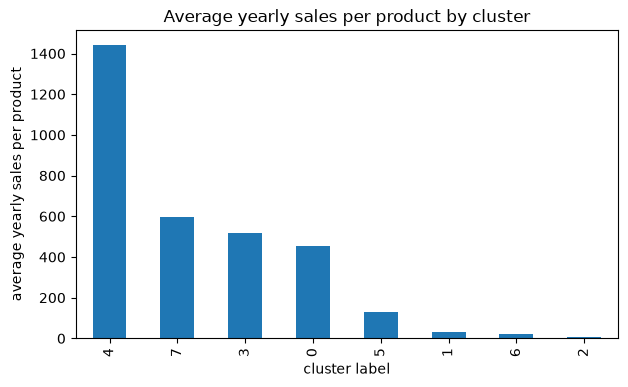

In [13]:
import matplotlib.pyplot as plt

# bar chart of the average yearly sales per product in each cluster
df_final['yearly_average_sales'].plot(kind='bar', figsize=(7, 4))
plt.xlabel('cluster label')
plt.ylabel('average yearly sales per product')
plt.title('Average yearly sales per product by cluster')
plt.show()

## Conclusion

In my run the table shows a big difference between the clusters. The best cluster (label 4) has 125 products that sold about 180,000 units in total, which is around 1,440 units per product in the year. At the other end, the weakest cluster (label 2) has 115 products with only about 760 units in total, or roughly 7 units per product. So the best group sells more than 200 times as much per product as the weakest one.

To put it in perspective, I can calculate the share of the total sales for each cluster:

In [14]:
# what percent of all products and of all sales does each cluster have?
share = pd.DataFrame({
    'pct_of_products': (df_final['count_product'] / df_final['count_product'].sum() * 100).round(1),
    'pct_of_sales': (df_final['total_sales'] / df_final['total_sales'].sum() * 100).round(1),
})
share

,pct_of_products,pct_of_sales
label,,
4,15.4,48.0
7,14.7,19.0
3,12.1,13.5
0,15.7,15.3
5,11.0,3.1
1,6.7,0.5
6,10.4,0.5
2,14.2,0.2


The top cluster is about 15% of the products but brings in about 48% of all the units sold. The three clusters at the bottom (labels 1, 6 and 2) are roughly a third of the catalog (253 products, about 31%) and together they add up to only about 1% of the sales (4,359 units out of 375,287). For a store this is useful: it shows which products carry the business and which ones barely sell, and those would be the first to look at when deciding what to promote or what to stop stocking.